<a href="https://colab.research.google.com/github/GerardoMunoz/Vision/blob/main/Autoencoder_Conv2D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
print("TensorFlow:", tf.__version__)
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
#x_train = x_train.reshape((-1, 784))
#x_test = x_test.reshape((-1, 784))
print("Entrenamiento:", x_train.shape, "Prueba:", x_test.shape)

TensorFlow: 2.21.0
Entrenamiento: (60000, 28, 28) Prueba: (10000, 28, 28)


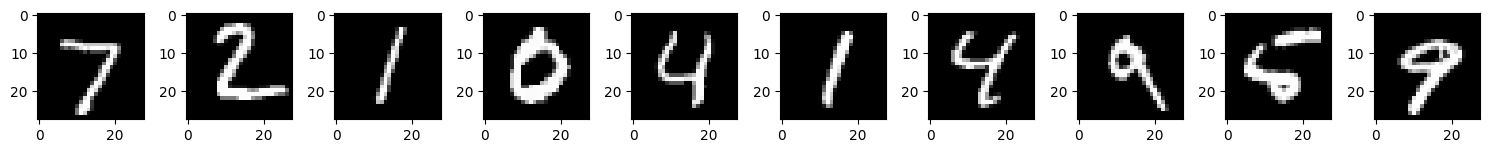

In [13]:
n = 10
fig, axes = plt.subplots(1, n, figsize=(15, 3))
for i in range(n):
    axes[ i].imshow(x_test[i].reshape(28, 28), cmap="gray")
plt.tight_layout(); plt.show()

In [14]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Redimensionamos los datos originales a 2D (28, 28, 1) para las capas convolucionales
x_train_conv = x_train.reshape((-1, 28, 28, 1))
x_test_conv = x_test.reshape((-1, 28, 28, 1))

latent_dim = 32

# --- ENCODER CONVOLUCIONAL ---
encoder= keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2), padding="same"), # Reduce a 14x14
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2), padding="same"), # Reduce a 7x7
    layers.Flatten(),
    layers.Dense(latent_dim, activation="relu", name="latent_vector")
], name="encoder")

# --- DECODER CONVOLUCIONAL ---
decoder = keras.Sequential([
    layers.Input(shape=(latent_dim,)),
    # Proyectamos de vuelta al tamaño del último mapa de características del encoder (7 * 7 * 64 = 3136)
    layers.Dense(7 * 7 * 64, activation="relu"),
    layers.Reshape((7, 7, 64)),
    # Usamos Conv2DTranspose para reconstruir y escalar las dimensiones
    layers.Conv2DTranspose(64, (3, 3), strides=2, activation="relu", padding="same"), # Escala a 14x14
    layers.Conv2DTranspose(32, (3, 3), strides=2, activation="relu", padding="same"), # Escala a 28x28
    layers.Conv2D(1, (3, 3), activation="sigmoid", padding="same") # Canal único de salida (gris)
], name="decoder")

# --- AUTOENCODER CONVOLUCIONAL ---
autoencoder = keras.Sequential([encoder, decoder], name="autoencoder")
autoencoder.compile(optimizer="adam", loss="binary_crossentropy")

# Mostramos el resumen de la nueva arquitectura
autoencoder_conv.summary(expand_nested=True)


Model: "autoencoder_conv"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_conv (Sequential)       │ (None, 32)             │       119,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2d (Conv2D)            │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ max_pooling2d              │ (None, 14, 14, 32)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2d_1 (Conv2D)          │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ max_pooling2d_1            │ (None, 7, 7, 64)       │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ flatten (Flatten)          │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ latent_vector (Dense)      │ (None, 32)             │       100,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_conv (Sequential)       │ (None, 28, 28, 1)      │       159,169 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ dense (Dense)              │ (None, 3136)           │       103,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ reshape (Reshape)          │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2d_transpose           │ (None, 14, 14, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2d_transpose_1         │ (None, 28, 28, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2d_2 (Conv2D)          │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 278,369 (1.06 MB)

 Trainable params: 278,369 (1.06 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_vector (Dense)           │ (None, 32)             │       100,384 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 119,200 (465.62 KB)

 Trainable params: 119,200 (465.62 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 3136)           │       103,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_2 (Reshape)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_4              │ (None, 14, 14, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_5              │ (None, 28, 28, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 159,169 (621.75 KB)

 Trainable params: 159,169 (621.75 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
autoencoder.summary(expand_nested=True)

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder (Sequential)            │ (None, 32)             │       119,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2d_6 (Conv2D)          │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ max_pooling2d_4            │ (None, 14, 14, 32)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2d_7 (Conv2D)          │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ max_pooling2d_5            │ (None, 7, 7, 64)       │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ flatten_2 (Flatten)        │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ latent_vector (Dense)      │ (None, 32)             │       100,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Sequential)            │ (None, 28, 28, 1)      │       159,169 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ dense_2 (Dense)            │ (None, 3136)           │       103,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ reshape_2 (Reshape)        │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2d_transpose_4         │ (None, 14, 14, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2d_transpose_5         │ (None, 28, 28, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2d_8 (Conv2D)          │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 278,369 (1.06 MB)

 Trainable params: 278,369 (1.06 MB)

 Non-trainable params: 0 (0.00 B)

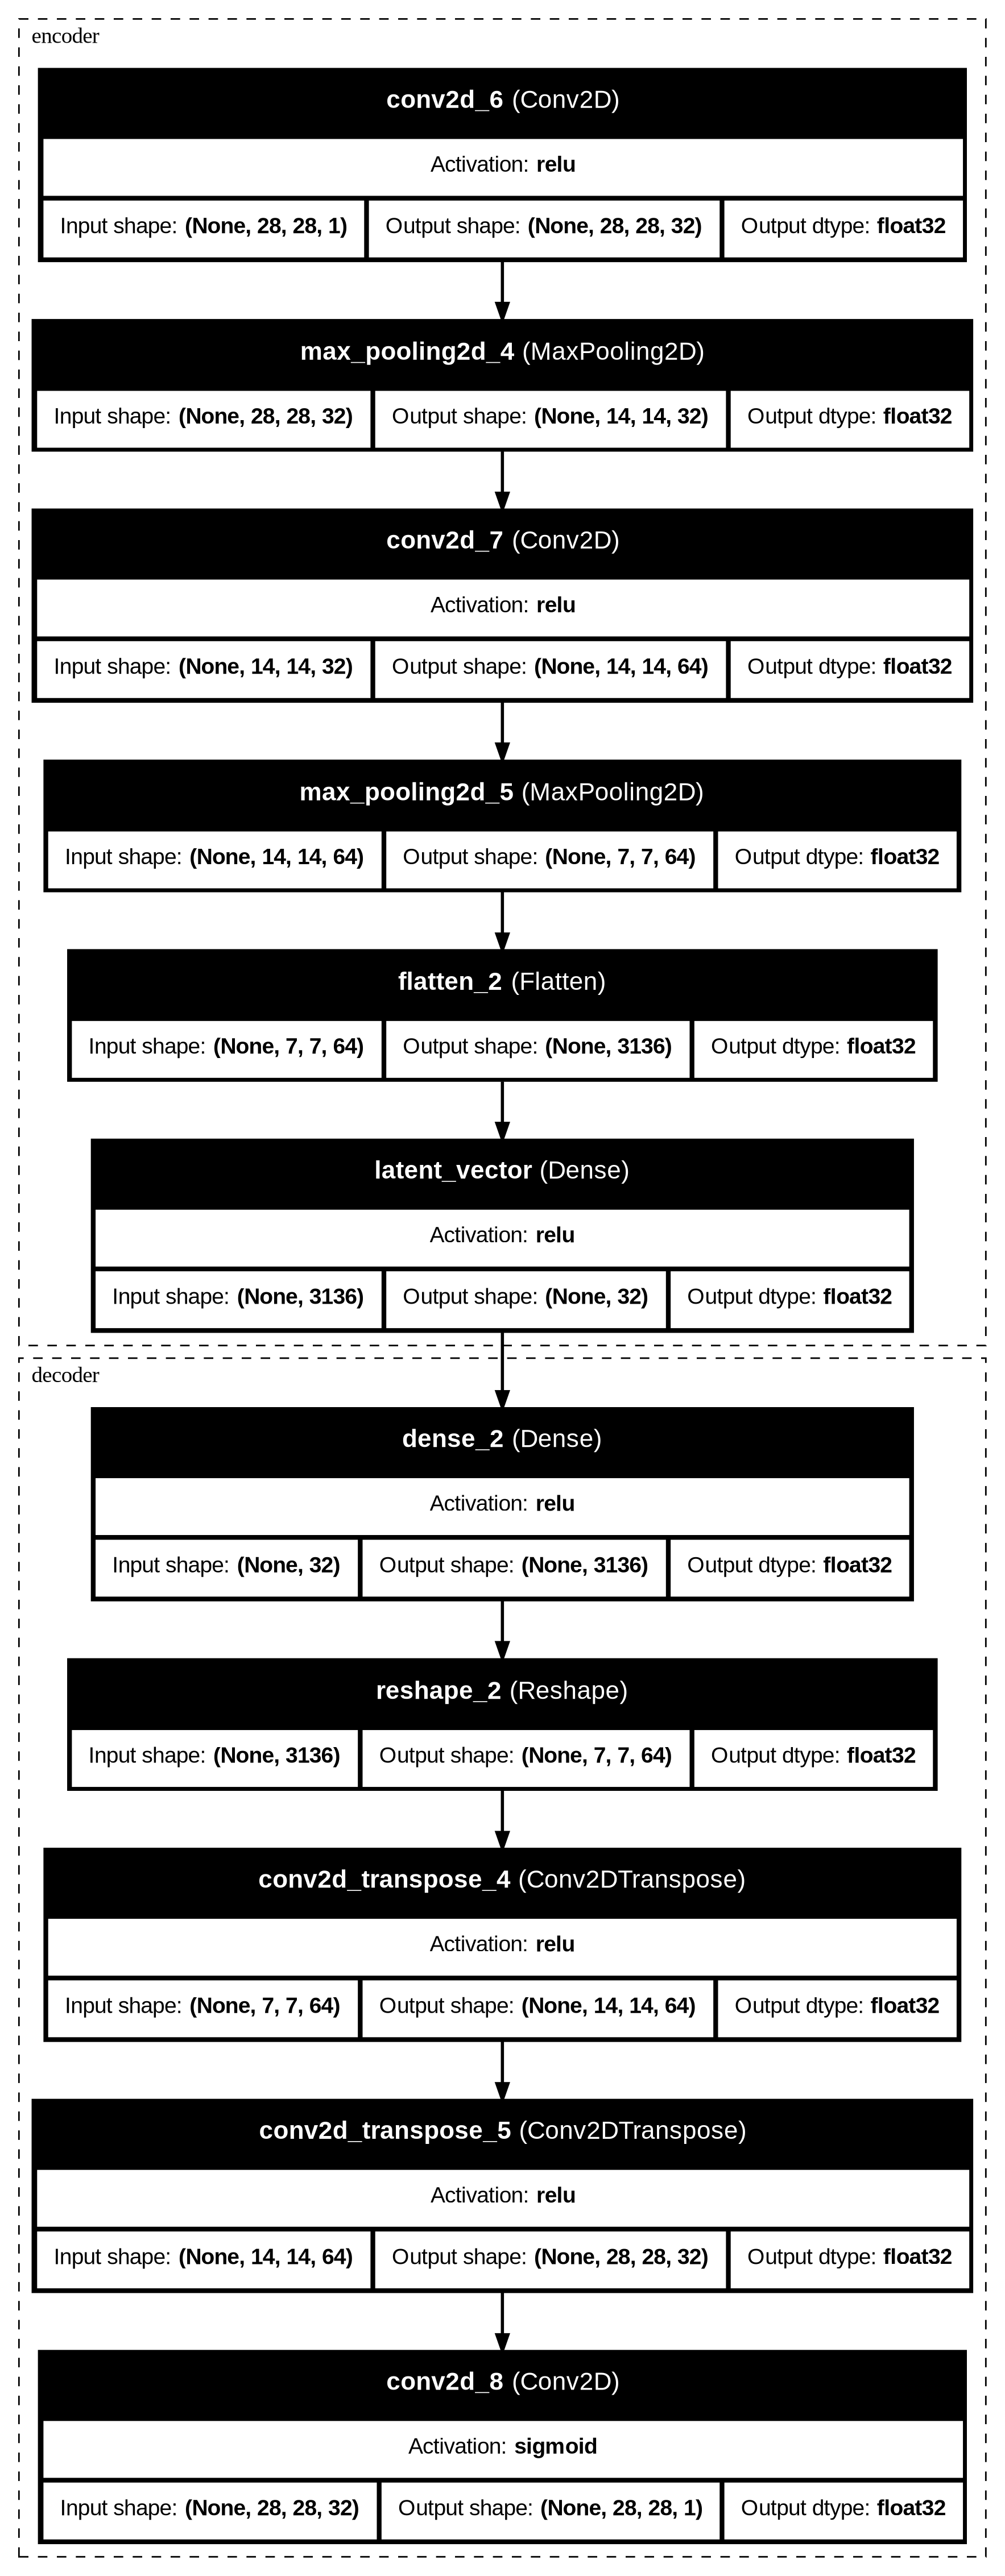

In [18]:
from tensorflow.keras.utils import plot_model

plot_model(
    autoencoder,
    show_shapes=True,
    show_layer_names=True,
    show_dtype=True,
    show_layer_activations=True,
    expand_nested=True,
    to_file='architecture.png'
)

In [19]:
loss_history = []
val_loss_history = []

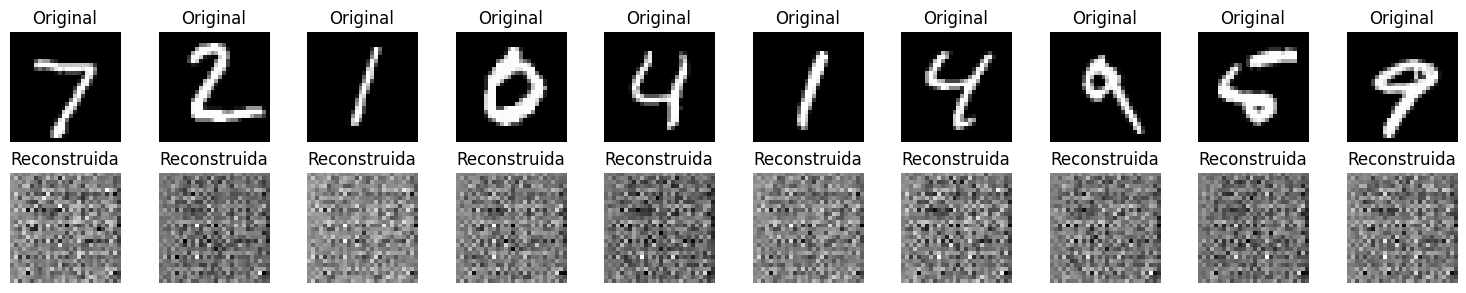

In [20]:
n = 10
reconstructions = autoencoder.predict(x_test[:n], verbose=0)
fig, axes = plt.subplots(2, n, figsize=(15, 3))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Reconstruida"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [21]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=1,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)
loss_history.extend(history.history['loss'])
val_loss_history.extend(history.history['val_loss'])

235/235 ━━━━━━━━━━━━━━━━━━━━ 185s 775ms/step - loss: 0.2332 - val_loss: 0.1264


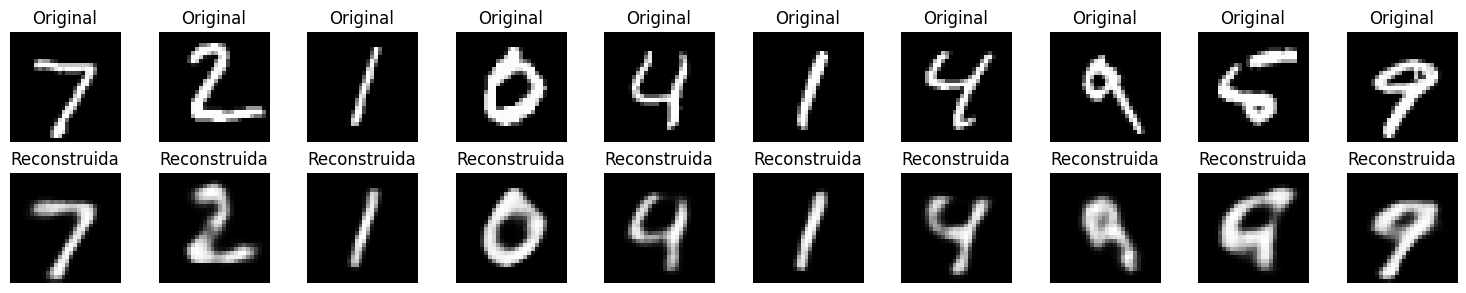

In [22]:
n = 10
reconstructions = autoencoder.predict(x_test[:n], verbose=0)
fig, axes = plt.subplots(2, n, figsize=(15, 3))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Reconstruida"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [23]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=1,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)
loss_history.extend(history.history['loss'])
val_loss_history.extend(history.history['val_loss'])

235/235 ━━━━━━━━━━━━━━━━━━━━ 179s 761ms/step - loss: 0.1098 - val_loss: 0.0983


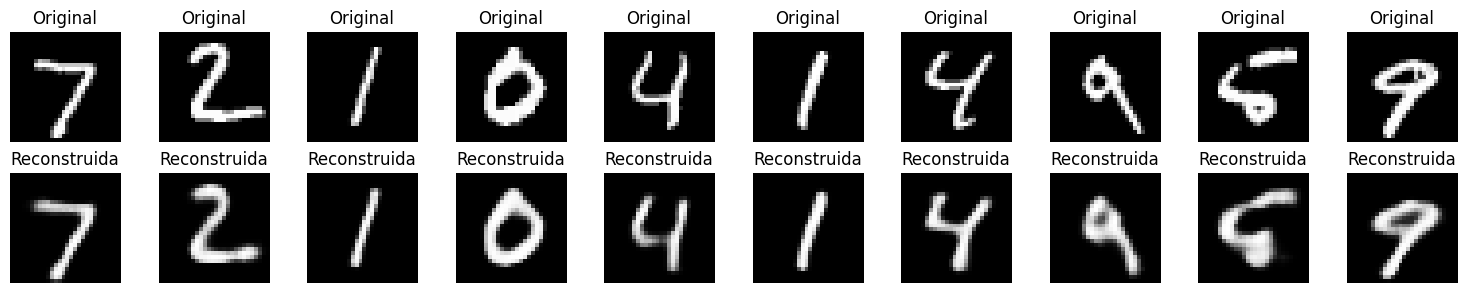

In [24]:
n = 10
reconstructions = autoencoder.predict(x_test[:n], verbose=0)
fig, axes = plt.subplots(2, n, figsize=(15, 3))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Reconstruida"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [25]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=1,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)
loss_history.extend(history.history['loss'])
val_loss_history.extend(history.history['val_loss'])

235/235 ━━━━━━━━━━━━━━━━━━━━ 179s 764ms/step - loss: 0.0950 - val_loss: 0.0904


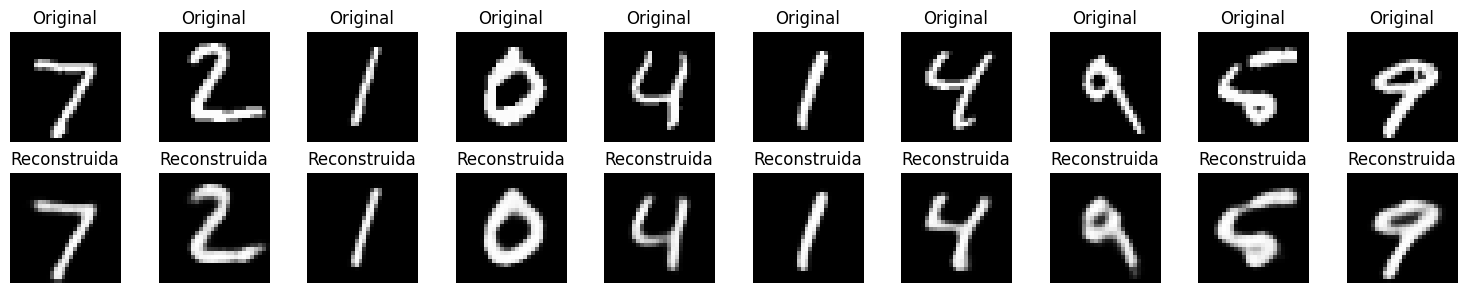

In [26]:
n = 10
reconstructions = autoencoder.predict(x_test[:n], verbose=0)
fig, axes = plt.subplots(2, n, figsize=(15, 3))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Reconstruida"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [27]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=1,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)
loss_history.extend(history.history['loss'])
val_loss_history.extend(history.history['val_loss'])

235/235 ━━━━━━━━━━━━━━━━━━━━ 180s 767ms/step - loss: 0.0892 - val_loss: 0.0867


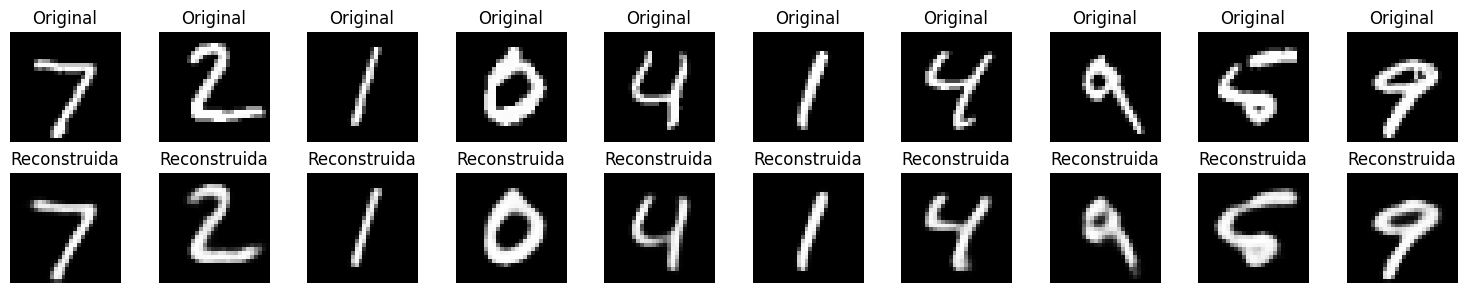

In [28]:
n = 10
reconstructions = autoencoder.predict(x_test[:n], verbose=0)
fig, axes = plt.subplots(2, n, figsize=(15, 3))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Reconstruida"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [29]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=1,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)
loss_history.extend(history.history['loss'])
val_loss_history.extend(history.history['val_loss'])

235/235 ━━━━━━━━━━━━━━━━━━━━ 180s 764ms/step - loss: 0.0863 - val_loss: 0.0847


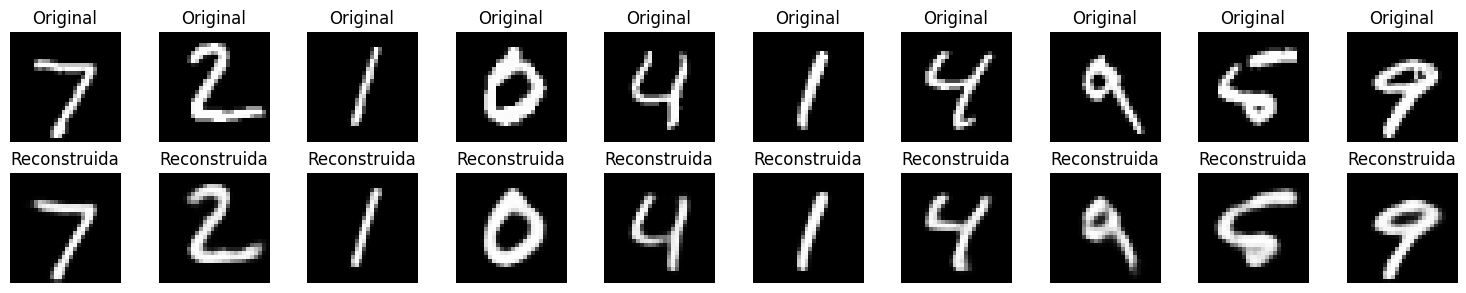

In [30]:
n = 10
reconstructions = autoencoder.predict(x_test[:n], verbose=0)
fig, axes = plt.subplots(2, n, figsize=(15, 3))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Reconstruida"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [31]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=1,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)
loss_history.extend(history.history['loss'])
val_loss_history.extend(history.history['val_loss'])

235/235 ━━━━━━━━━━━━━━━━━━━━ 180s 766ms/step - loss: 0.0844 - val_loss: 0.0827


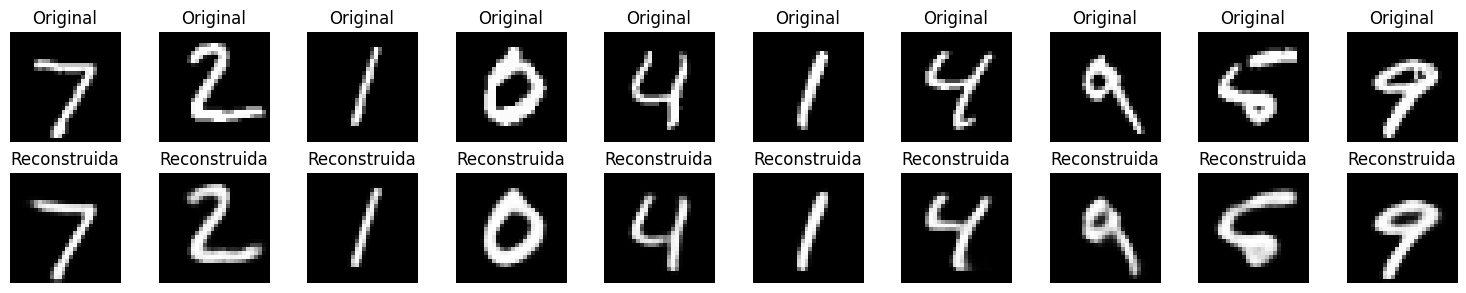

In [32]:
n = 10
reconstructions = autoencoder.predict(x_test[:n], verbose=0)
fig, axes = plt.subplots(2, n, figsize=(15, 3))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Reconstruida"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [33]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=1,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)
loss_history.extend(history.history['loss'])
val_loss_history.extend(history.history['val_loss'])

235/235 ━━━━━━━━━━━━━━━━━━━━ 182s 774ms/step - loss: 0.0828 - val_loss: 0.0810


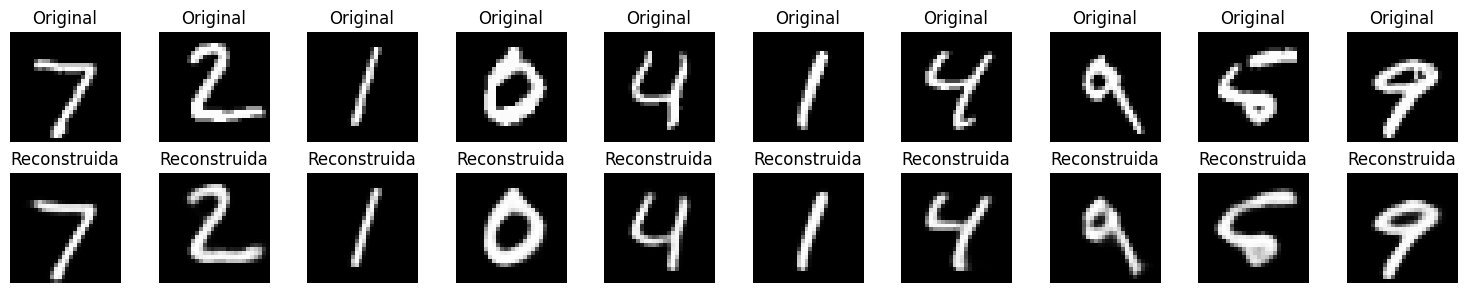

In [34]:
n = 10
reconstructions = autoencoder.predict(x_test[:n], verbose=0)
fig, axes = plt.subplots(2, n, figsize=(15, 3))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Reconstruida"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [35]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=1,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)
loss_history.extend(history.history['loss'])
val_loss_history.extend(history.history['val_loss'])

235/235 ━━━━━━━━━━━━━━━━━━━━ 184s 784ms/step - loss: 0.0812 - val_loss: 0.0803


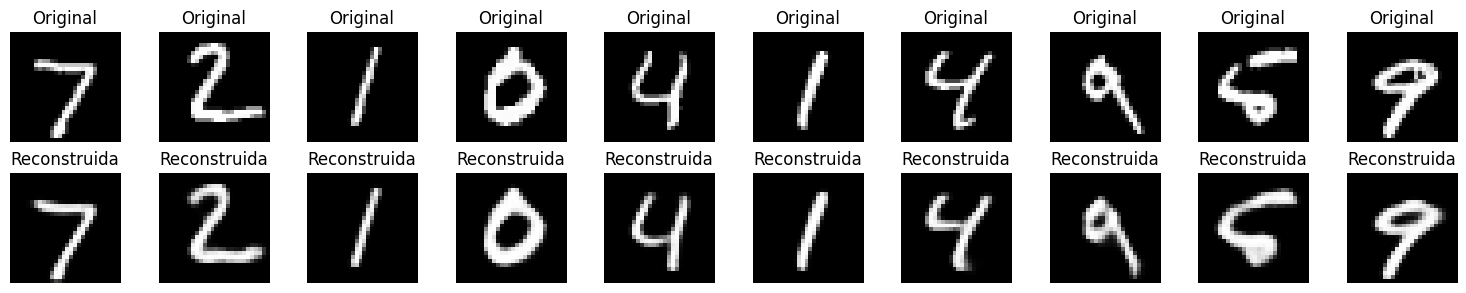

In [36]:
n = 10
reconstructions = autoencoder.predict(x_test[:n], verbose=0)
fig, axes = plt.subplots(2, n, figsize=(15, 3))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Reconstruida"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [37]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=1,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)
loss_history.extend(history.history['loss'])
val_loss_history.extend(history.history['val_loss'])

235/235 ━━━━━━━━━━━━━━━━━━━━ 185s 787ms/step - loss: 0.0802 - val_loss: 0.0793


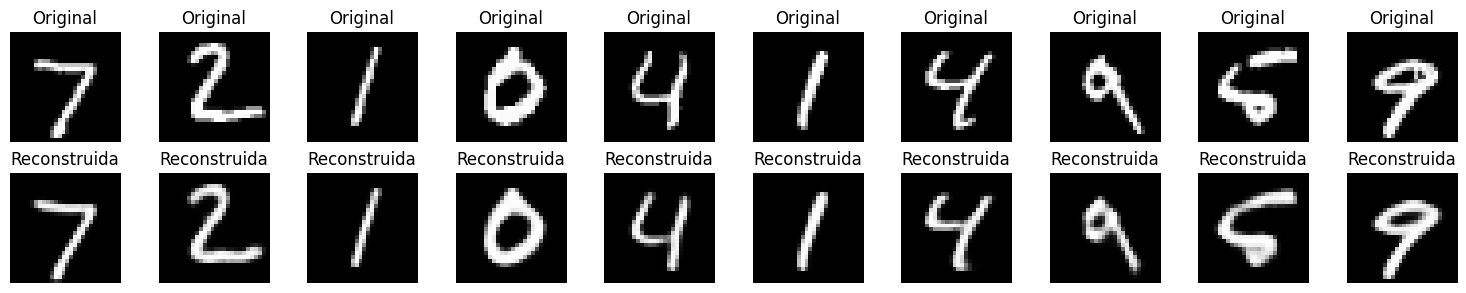

In [38]:
n = 10
reconstructions = autoencoder.predict(x_test[:n], verbose=0)
fig, axes = plt.subplots(2, n, figsize=(15, 3))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Reconstruida"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=1,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)
loss_history.extend(history.history['loss'])
val_loss_history.extend(history.history['val_loss'])

220/235 ━━━━━━━━━━━━━━━━━━━━ 11s 735ms/step - loss: 0.0795

In [ ]:
n = 10
reconstructions = autoencoder.predict(x_test[:n], verbose=0)
fig, axes = plt.subplots(2, n, figsize=(15, 3))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Reconstruida"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [41]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=1,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)
loss_history.extend(history.history['loss'])
val_loss_history.extend(history.history['val_loss'])

235/235 ━━━━━━━━━━━━━━━━━━━━ 181s 770ms/step - loss: 0.0789 - val_loss: 0.0784


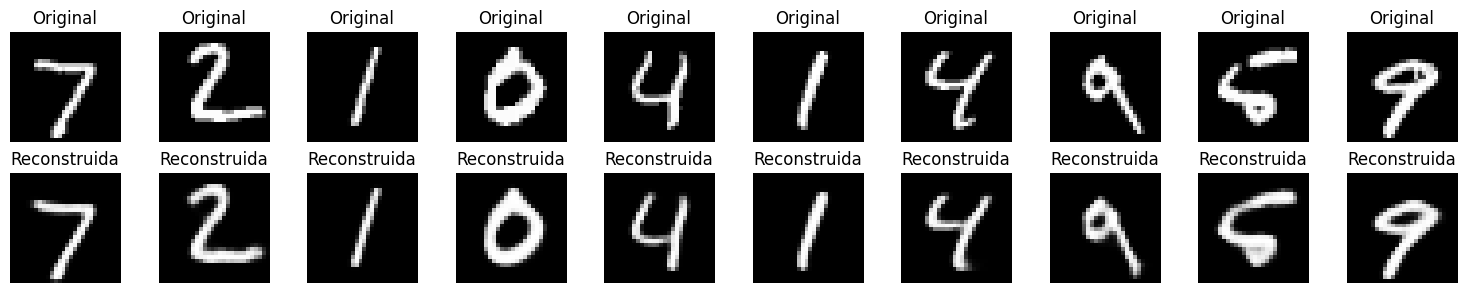

In [42]:
n = 10
reconstructions = autoencoder.predict(x_test[:n], verbose=0)
fig, axes = plt.subplots(2, n, figsize=(15, 3))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Reconstruida"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [43]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=1,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)
loss_history.extend(history.history['loss'])
val_loss_history.extend(history.history['val_loss'])

235/235 ━━━━━━━━━━━━━━━━━━━━ 183s 777ms/step - loss: 0.0784 - val_loss: 0.0779


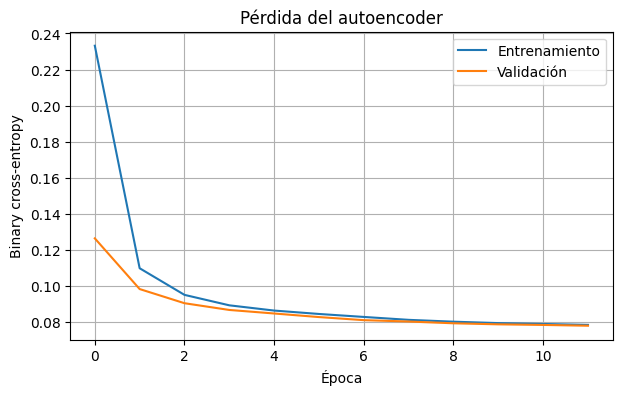

In [46]:
plt.figure(figsize=(7, 4))
plt.plot(loss_history, label="Entrenamiento")
plt.plot(val_loss_history, label="Validación")
plt.xlabel("Época"); plt.ylabel("Binary cross-entropy")
plt.title("Pérdida del autoencoder"); plt.legend(); plt.grid(True)
plt.show()

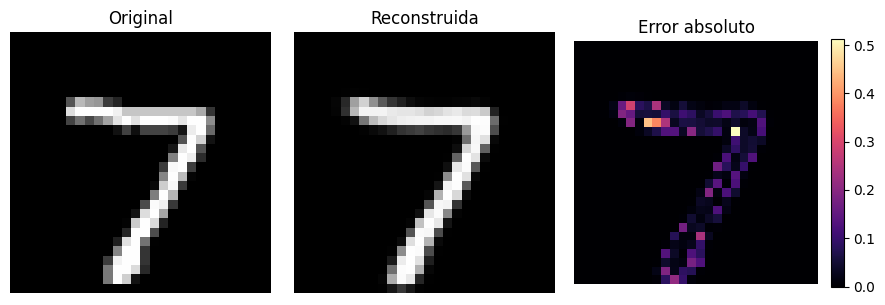

ValueError: operands could not be broadcast together with shapes (10000,28,28) (10000,28,28,1) 

In [47]:
idx = 0
original = x_test[idx].reshape(28, 28)
reconstructed = reconstructions[idx].reshape(28, 28)
error_map = np.abs(original - reconstructed)
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(original, cmap="gray"); axes[0].set_title("Original")
axes[1].imshow(reconstructed, cmap="gray"); axes[1].set_title("Reconstruida")
im = axes[2].imshow(error_map, cmap="magma"); axes[2].set_title("Error absoluto")
for ax in axes: ax.axis("off")
fig.colorbar(im, ax=axes[2], fraction=0.046)
plt.tight_layout(); plt.show()
pred = autoencoder.predict(x_test, verbose=0)
mse = np.mean((x_test - pred)**2, axis=1)
print(f"MSE promedio en test: {mse.mean():.6f}")

In [ ]:
z = encoder.predict(x_test[:2000], verbose=0)
plt.figure(figsize=(6, 5))
plt.scatter(z[:, 0], z[:, 1], c=y_test[:2000], cmap="tab10", s=8, alpha=0.7)
plt.colorbar(label="Clase (dígito)")
plt.xlabel("Dimensión latente 1"); plt.ylabel("Dimensión latente 2")
plt.title("Dos coordenadas del espacio latente")
plt.show()

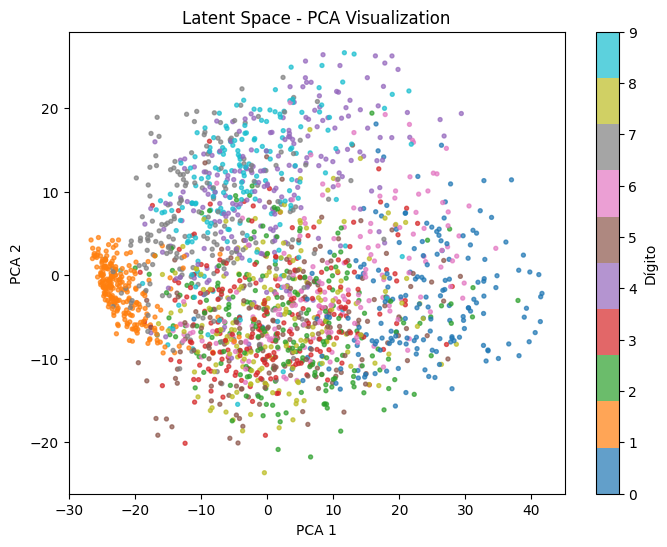

Varianza explicada: 0.38745695


In [48]:
from sklearn.decomposition import PCA

z = encoder.predict(x_test[:2000], verbose=0)

pca = PCA(n_components=2)
z_2d = pca.fit_transform(z)

plt.figure(figsize=(8, 6))

plt.scatter(
    z_2d[:, 0],
    z_2d[:, 1],
    c=y_test[:2000],
    cmap="tab10",
    s=8,
    alpha=0.7
)

plt.colorbar(label="Dígito")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("Latent Space - PCA Visualization")
plt.show()

print("Varianza explicada:", pca.explained_variance_ratio_.sum())

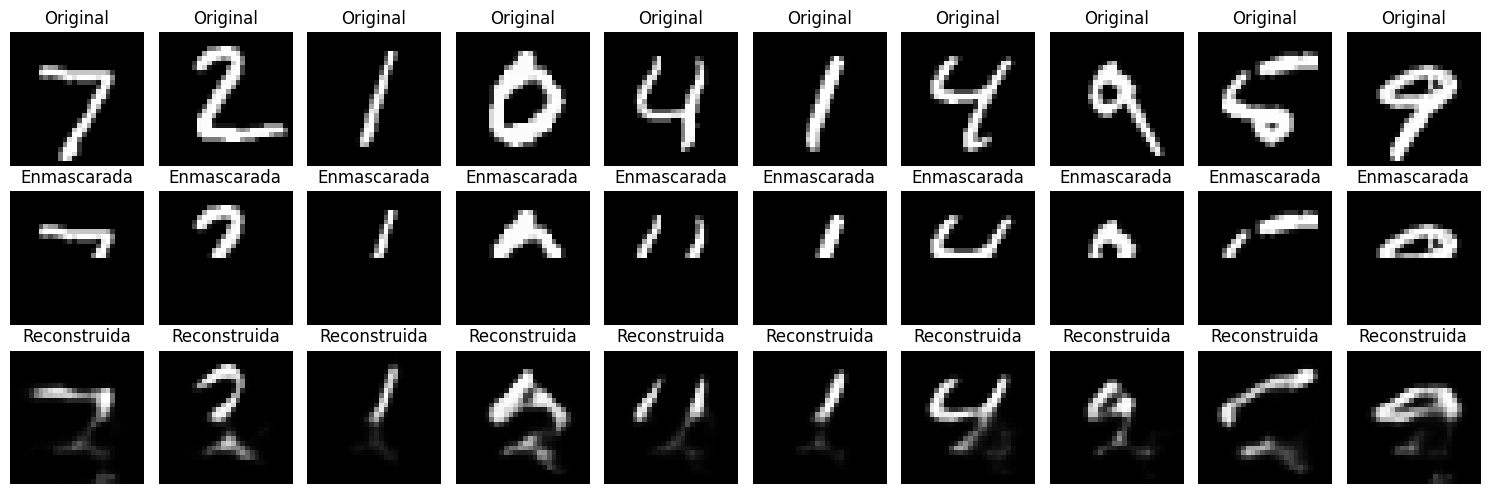

In [50]:
n = 10
x_test_masked = x_test[:n].copy()

# Aplicamos una máscara simple (poniendo a cero la mitad superior de la imagen: filas de 0 a 14)
for i in range(n):
    img_grid = x_test_masked[i].reshape(28, 28)
    img_grid[14:, :] = 0.0
    x_test_masked[i] = img_grid

# Predecimos la reconstrucción a partir de las imágenes enmascaradas
reconstructions_masked = autoencoder.predict(x_test_masked, verbose=0)

# Visualización
fig, axes = plt.subplots(3, n, figsize=(15, 5))
for i in range(n):
    # Fila 1: Imagen Original sin máscara
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    # Fila 2: Imagen con Máscara
    axes[1, i].imshow(x_test_masked[i].reshape(28, 28), cmap="gray")
    axes[1, i].set_title("Enmascarada")
    axes[1, i].axis("off")

    # Fila 3: Reconstrucción
    axes[2, i].imshow(reconstructions_masked[i].reshape(28, 28), cmap="gray")
    axes[2, i].set_title("Reconstruida")
    axes[2, i].axis("off")

plt.tight_layout()
plt.show()